## Tại đây chúng ta sẽ sử dụng thư viện chung

In [3]:
import numpy as np # linear algebra
import pandas as pd # data processing,
import matplotlib.pyplot as plt   # data visualization
import seaborn as sns             # statistical data visualization
import statsmodels.api as sm
import plotly.express as px
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
from statsmodels.tsa.stattools import acf, pacf
from statsmodels.tsa.stattools import adfuller
from statsmodels.tsa.seasonal import seasonal_decompose, STL
from statsmodels.stats.diagnostic import acorr_ljungbox
from pathlib import Path
output_dir = Path("../outputs")

## Data Processing

In [4]:
df = pd.read_csv("../data/daily-min-temperatures.csv")

FileNotFoundError: [Errno 2] No such file or directory: '../data/daily-min-temperatures.csv'

In [ ]:
df[df.columns[0:2]]

,Date,Temp
0,1981-01-01,20.7
1,1981-01-02,17.9
2,1981-01-03,18.8
3,1981-01-04,14.6
4,1981-01-05,15.8
...,...,...
3645,1990-12-27,14.0
3646,1990-12-28,13.6
3647,1990-12-29,13.5
3648,1990-12-30,15.7


In [ ]:
df['Date'] = pd.to_datetime(df['Date'])

In [ ]:
df = df.set_index('Date') # Chuyển sang lấy cột Date làm cột chính

In [ ]:
df = df.asfreq('D') # Vì là dữ liệu theo ngày nên set 'D' hay Day

In [ ]:
df['Temp'] = df['Temp'].interpolate()

In [ ]:
df

,Temp
Date,
1981-01-01,20.7
1981-01-02,17.9
1981-01-03,18.8
1981-01-04,14.6
1981-01-05,15.8
...,...
1990-12-27,14.0
1990-12-28,13.6
1990-12-29,13.5


## Bài tập 1

### Tải và xem trước dữ liệu

In [ ]:
# Nhớ kiểm tra  (head, info, plot).
print(df.head(10))
print(df.info())
print(df.describe())
print("Missing:", df.isna().sum().to_dict())


df['Temp'].plot(figsize=(12, 4), title="Daily Min Temperatures")
plt.xlabel("Date"); plt.ylabel("Temp"); 

plt.savefig(output_dir / "figure_01.png", dpi=300, bbox_inches="tight")

plt.show()

NameError: name 'df' is not defined

#### Ghi chú đồ thị: Line chart – chuỗi nhiệt độ gốc

- **Công dụng**
  - Nhìn tổng quan toàn bộ chuỗi
  - Phát hiện xu hướng, mùa vụ, điểm bất thường, đoạn thiếu dữ liệu
- **Ưu điểm**
  - Đơn giản, ngắn gọn
  - Thấy ngay chu kỳ lên xuống theo năm
- **Nhược điểm**
  - 3650 điểm theo ngày → đường dày đặc, nhiễu, khó thấy chi tiết
  - Chỉ cảm nhận bằng mắt, chưa đủ để kết luận chuỗi dừng hay không

### Tính ACF, PACF đến 40 lags

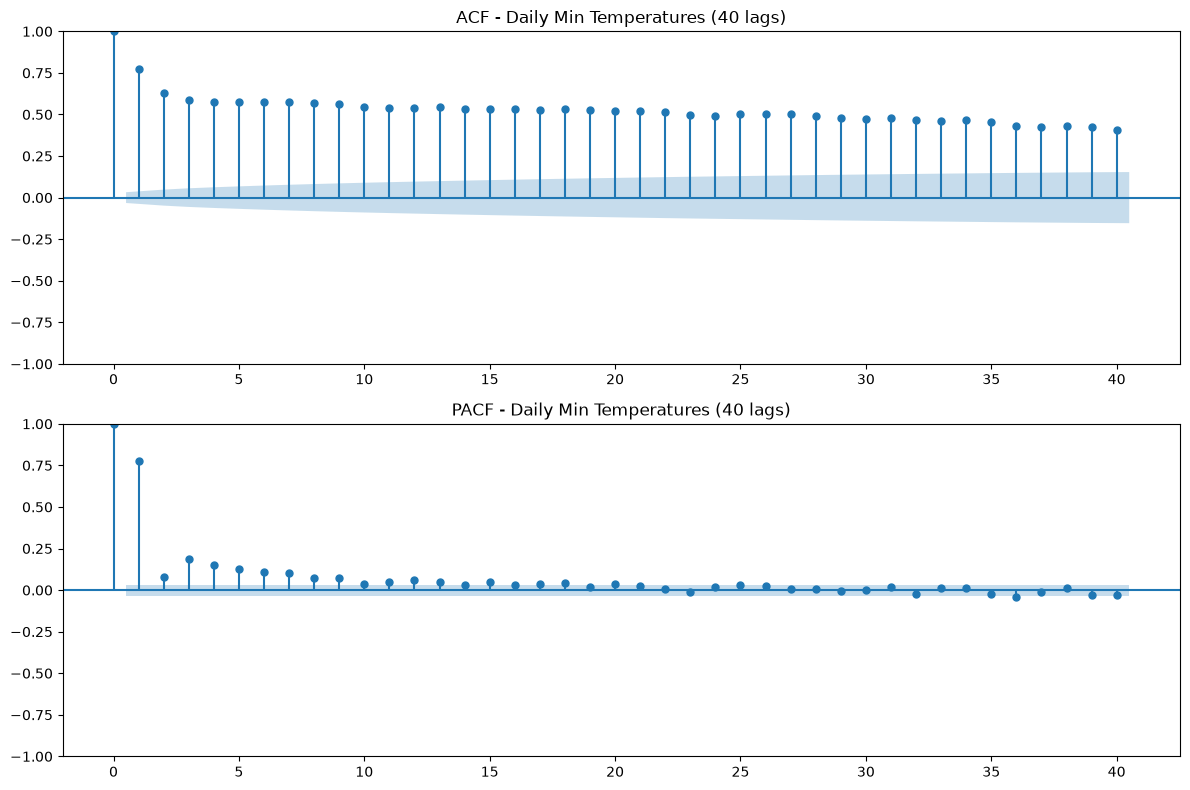

ACF: [1.     0.7744 0.6304 0.5854 0.578  0.5774 0.5755 0.5745 0.5671 0.5607
 0.547  0.5389 0.5413 0.5423 0.5358 0.5337 0.5308 0.5298 0.5309 0.5243
 0.523  0.5221 0.5134 0.498  0.4938 0.5003 0.5053 0.5002 0.4912 0.4804
 0.4742 0.4763 0.4646 0.4626 0.466  0.4546 0.4323 0.4219 0.4285 0.4222
 0.4075]
PACF: [ 1.      0.7746  0.0769  0.1894  0.1526  0.1295  0.1104  0.1023  0.0727
  0.0711  0.0371  0.0492  0.0615  0.048   0.0317  0.0467  0.0331  0.0401
  0.0413  0.0174  0.0374  0.0272  0.0061 -0.0092  0.0171  0.0307  0.0264
  0.007   0.0048 -0.0056  0.0022  0.0187 -0.026   0.0141  0.0138 -0.0243
 -0.0408 -0.0131  0.0139 -0.028  -0.0309]


In [ ]:
# Code tại đây

fig, axes = plt.subplots(2, 1, figsize=(12, 8))
plot_acf(df['Temp'], lags=40, ax=axes[0])
axes[0].set_title("ACF - Daily Min Temperatures (40 lags)")
plot_pacf(df['Temp'], lags=40, ax=axes[1])
axes[1].set_title("PACF - Daily Min Temperatures (40 lags)")
plt.tight_layout(); 

plt.savefig(output_dir / "figure_01_1.png", dpi=300, bbox_inches="tight")

plt.show()

print("ACF:", acf(df['Temp'], nlags=40, fft=True).round(4))
print("PACF:", pacf(df['Temp'], nlags=40).round(4))

#### Ghi chú đồ thị: ACF & PACF (40 lags)

- **Công dụng**
  - ACF: tương quan giữa hôm nay và k ngày trước (cả trực tiếp lẫn gián tiếp)
  - PACF: tương quan trực tiếp, đã loại ảnh hưởng của các lag ở giữa
  - Gợi ý bậc q (từ ACF) và p (từ PACF) cho ARIMA
- **Ưu điểm**
  - Có dải tin cậy 95% → biết lag nào có ý nghĩa thống kê
  - ACF giảm chậm → nhận ra ngay chuỗi có trend / không dừng
- **Nhược điểm**
  - Chỉ đọc p, q chính xác khi chuỗi đã dừng; chuỗi gốc làm ACF cao ở mọi lag
  - 40 lag quá ngắn với dữ liệu ngày → không thấy mùa vụ năm (lag 365)
  - Đánh giá "cắt cụt" ở lag nào vẫn mang tính chủ quan

### Kết luận
Kết luận
1. Tự tương quan mạnh? Có. ACF lag1 = 0.77, toàn bộ 40 lag đều có ý nghĩa thống kê. Chuỗi có "trí nhớ" ngắn hạn rất tốt — giá trị hôm nay phụ thuộc mạnh vào hôm qua.
2. Xu hướng / mùa vụ?  ACF giảm chậm → trend / non-stationary. Đây đúng là trường hợp này (0.77 → 0.41 sau 40 lag, giảm rất chậm). Không thấy mùa vụ trong cửa sổ 40 lag: không có đỉnh lặp lại rõ (lag7 ≈ 0.574 ngang bằng lân cận, không phải peak). Mùa vụ năm (lag 365) nằm ngoài phạm vi 40 lag nên chưa kiểm tra được. nhưng khi chạy thử lag 365 thì AFC có đỉnh theo chu kì-> đây là pattern chuẩn của nhiệt độ ngày theo mùa.
3. Lag quan trọng nhất? Lag1 (cả ACF và PACF đều ~0.77). PACF "cắt" mạnh sau lag1 với vài lag nhỏ tiếp theo (2–9)


## Bài tập 2


### 1. Sinh dữ liệu white noise bằng NumPy (1000 điểm)


Số điểm: 1000
Trung bình: 0.019 | Độ lệch chuẩn: 0.979


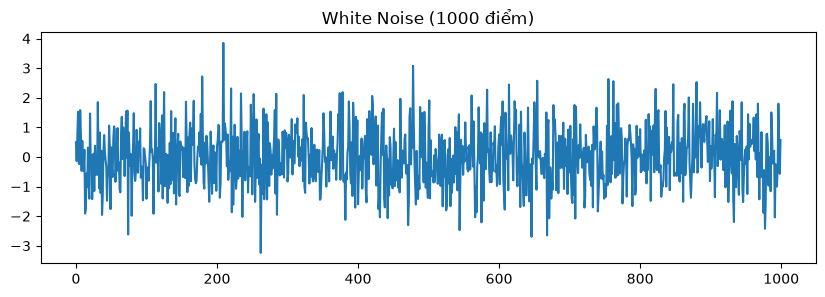

In [ ]:
np.random.seed(42)
wn = np.random.normal(loc=0, scale=1, size=1000)

print("Số điểm:", len(wn))
print("Trung bình:", round(wn.mean(), 3), "| Độ lệch chuẩn:", round(wn.std(), 3))

plt.figure(figsize=(10, 3))
plt.plot(wn)
plt.title("White Noise (1000 điểm)")

plt.savefig(output_dir / "figure_02.png", dpi=300, bbox_inches="tight")

plt.show()

#### Ghi chú đồ thị: Line chart – White noise

- **Công dụng**
  - Tạo chuỗi hoàn toàn ngẫu nhiên làm "mẫu chuẩn" để so sánh
- **Ưu điểm**
  - Biết trước đáp án (mean = 0, std = 1, không tự tương quan) → dùng để kiểm chứng công cụ
  - `np.random.seed(42)` → chạy lại ra đúng kết quả cũ
- **Nhược điểm**
  - Nhìn line chart không phân biệt được white noise với chuỗi tự tương quan yếu → cần ACF
  - Dữ liệu giả lập, không đại diện cho dữ liệu thực tế

### 2. Vẽ ACF -> kiểm tra xem các lag có nằm trong ngưỡng tin cậy 95% không


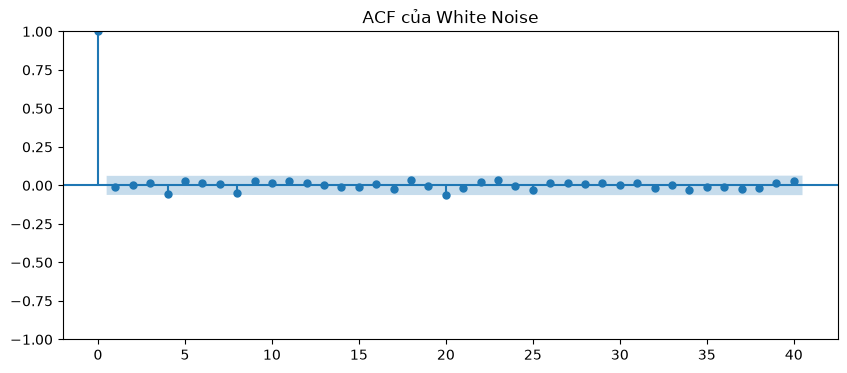

Ngưỡng tin cậy 95%: ±0.062
Số lag vượt ngưỡng: 1/40


In [ ]:
fig, ax = plt.subplots(figsize=(10, 4))
plot_acf(wn, lags=40, alpha=0.05, ax=ax)
ax.set_title("ACF của White Noise")

plt.savefig(output_dir / "figure_02_1.png", dpi=300, bbox_inches="tight")

plt.show()

vals = acf(wn, nlags=40)[1:]          # bỏ lag 0 (luôn bằng 1)
bound = 1.96 / np.sqrt(len(wn))
so_lag_vuot = np.sum(np.abs(vals) > bound)
print(f"Ngưỡng tin cậy 95%: ±{bound:.3f}")
print(f"Số lag vượt ngưỡng: {so_lag_vuot}/40")

#### Ghi chú đồ thị: ACF – White noise

- **Công dụng**
  - Kiểm tra một chuỗi có phải white noise: gần như mọi lag nằm trong dải ±1.96/√n
  - Sau này dùng y hệt cách này để kiểm tra residual của mô hình
- **Ưu điểm**
  - Có ngưỡng cụ thể (±0.062 với n = 1000), dễ đếm số lag vượt
- **Nhược điểm**
  - Dù là white noise thật vẫn có ~5% lag vượt ngưỡng do ngẫu nhiên (ở đây 1/40) → dễ kết luận nhầm
  - Xét từng lag riêng lẻ → nên kèm Ljung-Box để kiểm định cả nhóm lag

### 3. So sánh ACF của white noise với ACF của chuỗi AirPassengers


Số điểm AirPassengers: 144


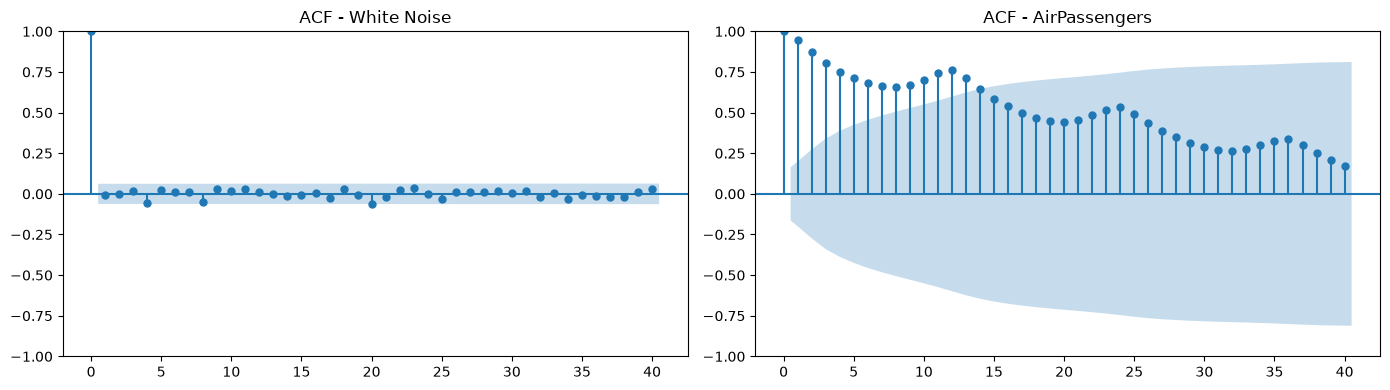

In [ ]:
# Tải AirPassengers (cần internet, Colab có sẵn)
ap = sm.datasets.get_rdataset("AirPassengers").data["value"]
print("Số điểm AirPassengers:", len(ap))   # kỳ vọng: 144

fig, axes = plt.subplots(1, 2, figsize=(14, 4))
plot_acf(wn, lags=40, ax=axes[0]); axes[0].set_title("ACF - White Noise")
plot_acf(ap, lags=40, ax=axes[1]); axes[1].set_title("ACF - AirPassengers")
plt.tight_layout()

plt.savefig(output_dir / "figure_02_3.png", dpi=300, bbox_inches="tight")

plt.show()

#### Ghi chú đồ thị: ACF – White noise vs AirPassengers

- **Công dụng**
  - Đặt cạnh nhau để thấy khác biệt giữa chuỗi không có cấu trúc và chuỗi có trend + mùa vụ
- **Ưu điểm**
  - So sánh trực tiếp trên cùng số lag
  - Thấy rõ 2 dấu hiệu: ACF giảm chậm (trend) và gợn ở lag 12, 24 (mùa vụ)
- **Nhược điểm**
  - Hai chuỗi khác độ dài (1000 vs 144) → dải tin cậy AirPassengers rộng hơn nhiều, so mức "vượt ngưỡng" giữa 2 hình phải cẩn thận
  - AirPassengers chưa sai phân → trend lấn át, mùa vụ chỉ thấy mờ

### 4. Viết 5 dòng mô tả sự khác nhau

In [ ]:
# 1. White noise chỉ có 1/40 lag vượt ngưỡng tin cậy 95% (±0.062), phần còn lại nằm trong dải tin cậy. ACF của AirPassengers có các lag đầu nằm hẳn ngoài dải tin cậy.

# 2. ACF của white noise dao động ngẫu nhiên quanh 0 và không theo quy luật nào. ACF của AirPassengers bắt đầu rất cao (gần 0.95 ở lag 1), giảm rất chậm và vẫn dương qua 40 lag.

# 3. White noise không có xu hướng, còn ACF giảm chậm của AirPassengers cho thấy chuỗi có xu hướng tăng dài hạn, tức là chuỗi không dừng.

# 4. AirPassengers có gợn nhẹ quanh lag 12 và 24 (tính mùa vụ theo năm), trong khi ACF của white noise không có chu kỳ nào.

# 5. White noise gồm các giá trị độc lập nên không thể dự báo từ quá khứ. AirPassengers có tự tương quan mạnh nên có thể mô hình hóa và dự báo.

## Bài tập 3

### 1. Chọn chuỗi dữ liệu theo tháng hoặc theo quý


In [ ]:
# Code tại đây
monthly = df['Temp'].resample('MS').mean()  # MS = Month Start
print(monthly.shape)
monthly.head()

(120,)


Date
1981-01-01    17.712903
1981-02-01    17.678571
1981-03-01    13.500000
1981-04-01    12.356667
1981-05-01     9.490323
Freq: MS, Name: Temp, dtype: float64

### 2. Dùng phương pháp STL hoặc classical decomposition


In [ ]:
# Code tại đây
### 2. Dùng STL decomposition (chu kỳ mùa vụ = 12 tháng)

stl = STL(monthly, period=12, robust=True)
result = stl.fit()

### 3. Vẽ 4 thành phần: Observed, Trend, Seasonal, Residual


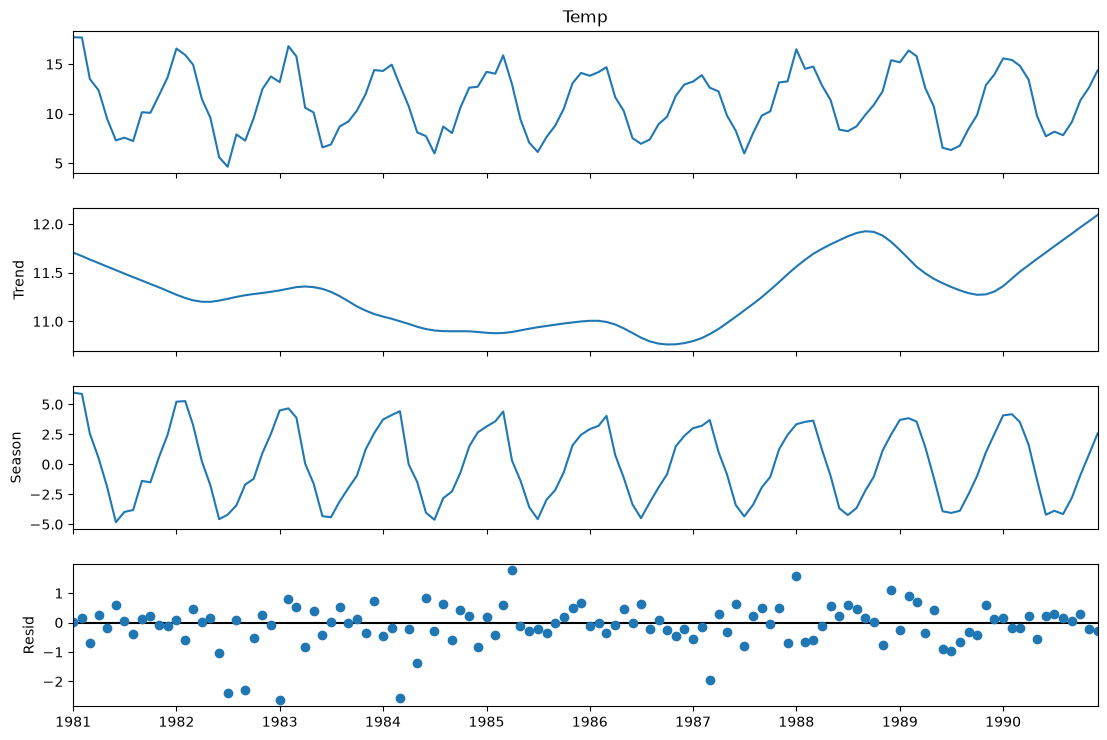

In [ ]:
# Code tại đây
fig = result.plot()
fig.set_size_inches(12, 8)

plt.savefig(output_dir / "figure_03.png", dpi=300, bbox_inches="tight")

plt.show()

#### Ghi chú đồ thị: STL decomposition

- **Công dụng**
  - Tách chuỗi thành Trend + Seasonal + Residual để xem riêng từng phần
- **Ưu điểm**
  - `robust=True` → ít bị outlier kéo lệch
  - Mùa vụ được phép thay đổi dần qua các năm (linh hoạt hơn classical decomposition)
  - Không mất dữ liệu ở 2 đầu chuỗi như classical
- **Nhược điểm**
  - Chỉ tách kiểu cộng (additive); muốn kiểu nhân phải lấy log trước
  - Phải tự chọn `period`; kết quả còn phụ thuộc độ trơn của trend/seasonal
  - Chỉ xử lý được 1 chu kỳ mùa vụ

### 4. Mô tả

Trend đầu chuỗi: 11.71 | cuối chuỗi: 12.09
Độ dốc: 0.0032 °C/tháng (~0.39 °C sau 10 năm)

Độ mạnh mùa vụ Fs = 0.950 (càng gần 1 càng mạnh)
Date
1     3.96
2     4.14
3     3.70
4     0.71
5    -1.35
6    -3.99
7    -4.28
8    -3.44
9    -2.08
10   -0.98
11    1.16
12    2.51
Name: season, dtype: float64

Mean residual: -0.0886 | Std: 0.6965


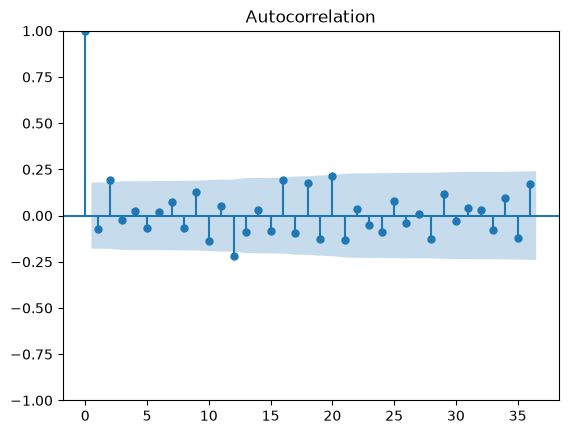

      lb_stat  lb_pvalue
12  18.787951   0.093776
24  45.513974   0.005062


In [ ]:
# Code tại đây
trend, seasonal, resid = result.trend, result.seasonal, result.resid

# --- Xu hướng tăng hay giảm? ---
slope = np.polyfit(np.arange(len(trend)), trend.values, 1)[0]
print(f"Trend đầu chuỗi: {trend.iloc[0]:.2f} | cuối chuỗi: {trend.iloc[-1]:.2f}")
print(f"Độ dốc: {slope:.4f} °C/tháng (~{slope*120:.2f} °C sau 10 năm)")

# --- Mùa vụ mạnh hay yếu? ---
Fs = max(0, 1 - resid.var() / (resid + seasonal).var())
print(f"\nĐộ mạnh mùa vụ Fs = {Fs:.3f} (càng gần 1 càng mạnh)")
print(seasonal.groupby(seasonal.index.month).mean().round(2))

# --- Residual có giống white noise không? ---
print("\nMean residual:", round(resid.mean(), 4), "| Std:", round(resid.std(), 4))
plot_acf(resid, lags=36)

plt.savefig(output_dir / "figure_03_1.png", dpi=300, bbox_inches="tight")

plt.show()

print(acorr_ljungbox(resid, lags=[12, 24], return_df=True))

#### Ghi chú đồ thị: ACF của residual (STL) + Ljung-Box

- **Công dụng**
  - Kiểm tra phần dư sau khi tách trend + mùa vụ còn sót quy luật không
- **Ưu điểm**
  - Chỉ ra lag nào còn tự tương quan (ở đây lag 12 → mùa vụ chưa tách hết)
  - Kết hợp Ljung-Box → có p-value để kết luận, không chỉ nhìn bằng mắt
- **Nhược điểm**
  - Đây là residual của phân rã, chưa phải residual của mô hình dự báo
  - Chuỗi tháng chỉ 120 điểm → dải tin cậy rộng (±0.18), khó phát hiện tự tương quan yếu

#### Nhận xét

- **Xu hướng:** Thành phần Trend tăng rất nhẹ, từ 11.71°C lên 12.09°C (độ dốc ≈ 0.0032°C/tháng,
  khoảng +0.39°C sau 10 năm). Mức thay đổi nhỏ so với biên độ mùa vụ nên có thể xem chuỗi
  gần như ổn định về mức trung bình, không có xu hướng tăng/giảm rõ rệt.

- **Mùa vụ:** Rất mạnh (Fs = 0.950). Thành phần Seasonal dao động khoảng ±4°C, lặp lại đều
  theo chu kỳ 12 tháng: nhiệt độ cao nhất vào tháng 1–3 (cao nhất tháng 2: +4.14) và thấp nhất
  vào tháng 6–8 (thấp nhất tháng 7: −4.28), phù hợp với khí hậu mùa hè/đông ở Nam bán cầu.
  Biên độ mùa vụ không đổi nhiều theo mức của chuỗi nên dùng mô hình phân rã cộng (additive).

- **Residual:** Dao động quanh 0 (mean = −0.09, std = 0.70), nhỏ hơn nhiều so với biên độ mùa vụ.
  Biểu đồ ACF cho thấy phần lớn các lag nằm trong khoảng tin cậy 95%, riêng lag 12 vượt ra ngoài.
  Kiểm định Ljung-Box cho p = 0.094 ở lag 12 nhưng p = 0.005 ở lag 24. Vì vậy residual
  gần giống white noise nhưng chưa hoàn toàn: vẫn còn một chút tự tương quan còn sót lại,
  có thể do cấu trúc mùa vụ chưa được tách hết.

- **Kết luận:** STL đã tách tốt phần lớn cấu trúc của chuỗi (trend + mùa vụ giải thích gần như
  toàn bộ biến động). Chuỗi có mùa vụ rõ nên phù hợp để dự báo bằng mô hình có thành phần mùa vụ như SARIMA.
  

## Bài tập 4

### 1. Tạo dữ liệu thiếu (NaN) giả lập hoặc dùng dataset có missing


In [ ]:
filename = "daily-min-temperatures.csv"

paths = [
    Path("data") / filename,
    Path("../data") / filename,
]

file_path = next((p for p in paths if p.is_file()), None)

if file_path is None:
    raise FileNotFoundError("Không tìm thấy file dữ liệu trong thư mục data")

df = pd.read_csv(
    file_path,
    parse_dates=["Date"],
    index_col="Date"
)

series = df["Temp"]

print(df.head())

series = df['Temp']

np.random.seed(42)
ts_missing = series.copy()
idx = np.random.choice(len(ts_missing), size=int(0.05*len(ts_missing)), replace=False)
ts_missing.iloc[idx] = np.nan
ts_missing.iloc[1000:1010] = np.nan

            Temp
Date            
1981-01-01  20.7
1981-01-02  17.9
1981-01-03  18.8
1981-01-04  14.6
1981-01-05  15.8


### 2. Kiểm tra missing: isna().sum()


In [ ]:
print(ts_missing.isna().sum())

191


### 3. Xử lý missing bằng 2 cách: Forward-fill và Interpolation


In [ ]:
ts_ffill = ts_missing.ffill()
ts_interp = ts_missing.interpolate(method='time')

### 4. Phát hiện outliers bằng: Rolling mean/variance; Z-score hoặc IQR


In [ ]:
roll_mean = ts_interp.rolling(30, center=True).mean()
roll_std = ts_interp.rolling(30, center=True).std()
out_roll = (ts_interp - roll_mean).abs() > 3 * roll_std

z = (ts_interp - ts_interp.mean()) / ts_interp.std()
out_z = z.abs() > 3

Q1, Q3 = ts_interp.quantile(0.25), ts_interp.quantile(0.75)
IQR = Q3 - Q1
out_iqr = (ts_interp < Q1 - 1.5*IQR) | (ts_interp > Q3 + 1.5*IQR)

print(out_roll.sum(), out_z.sum(), out_iqr.sum())

4 8 14


### 5. Vẽ trước và sau khi xử lý

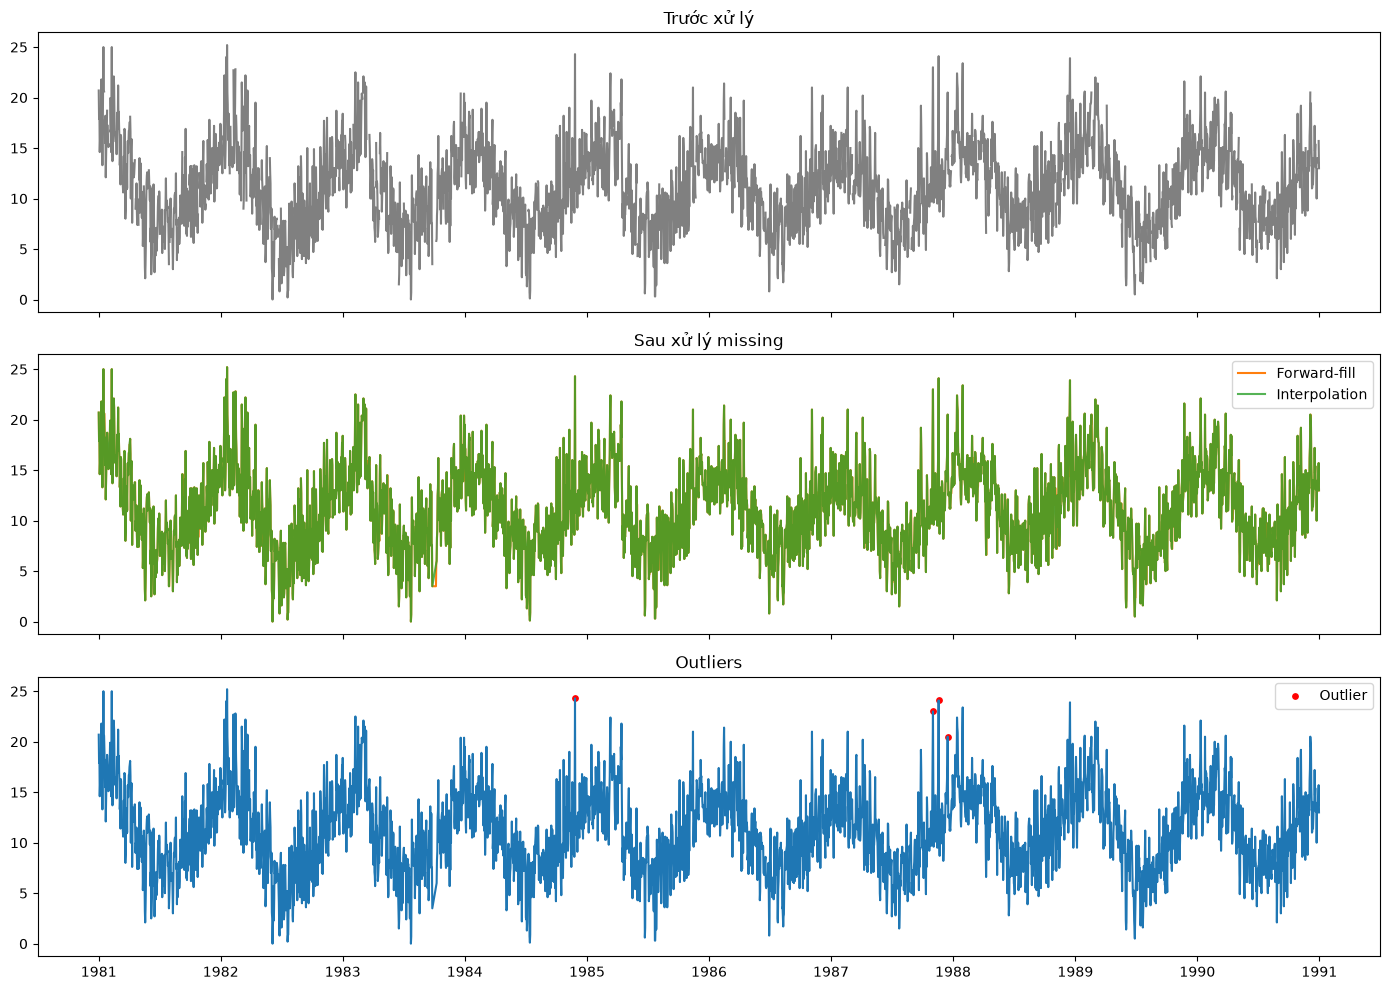

In [ ]:
fig, axes = plt.subplots(3, 1, figsize=(14, 10), sharex=True)

axes[0].plot(ts_missing, color='gray')
axes[0].set_title('Trước xử lý')

axes[1].plot(ts_ffill, color='tab:orange', label='Forward-fill')
axes[1].plot(ts_interp, color='tab:green', alpha=0.8, label='Interpolation')
axes[1].set_title('Sau xử lý missing')
axes[1].legend()

axes[2].plot(ts_interp, color='tab:blue')
axes[2].scatter(ts_interp.index[out_roll], ts_interp[out_roll], color='red', s=15, label='Outlier')
axes[2].set_title('Outliers')
axes[2].legend()

plt.tight_layout()

plt.savefig(output_dir / "figure_04.png", dpi=300, bbox_inches="tight")

plt.show()

#### Ghi chú đồ thị: Trước / sau xử lý missing + outliers

- **Công dụng**
  - So sánh 2 cách điền missing: forward-fill vs interpolation
  - Đánh dấu outlier trên chuỗi đã xử lý
- **Ưu điểm**
  - 3 panel dùng chung trục thời gian (`sharex=True`) → so trực tiếp trước/sau
  - Thấy rõ vị trí đoạn thiếu liên tiếp
- **Nhược điểm**
  - 3650 điểm → đường ffill và interpolation gần như trùng nhau; nên zoom `iloc[990:1020]` để thấy khác biệt (ffill tạo bậc phẳng, interpolation nối thẳng)
  - Panel outlier chỉ hiện phương pháp rolling, chưa so với Z-score và IQR

## Bài tập 5

### 1. Vẽ line chart toàn bộ chuỗi


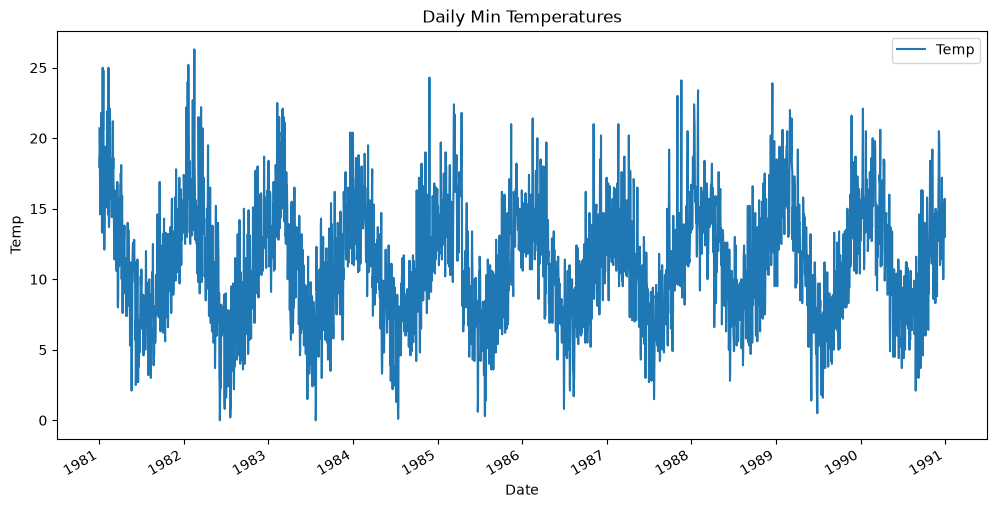

In [ ]:
# Code tại đây

df.plot(figsize=(12, 6), title="Daily Min Temperatures")
plt.xlabel("Date"); plt.ylabel("Temp"); 

plt.savefig(output_dir / "figure_05.png", dpi=300, bbox_inches="tight")

plt.show()

#### Ghi chú đồ thị: Line chart – toàn bộ chuỗi

- **Công dụng**
  - Làm nền để đối chiếu với rolling, seasonal và heatmap phía sau
- **Ưu điểm**
  - Thấy dao động đều theo năm, biên độ gần như không đổi → hợp với mô hình cộng (additive)
- **Nhược điểm**
  - Giống đồ thị Bài tập 1: dày đặc, khó đọc chi tiết
  - Có thể vẽ thêm bản trung bình tháng (`resample('MS').mean()`) cho dễ nhìn

### 2. Vẽ rolling mean (window=12) và rolling std


Date
1981-01-01          NaN
1981-01-02          NaN
1981-01-03          NaN
1981-01-04          NaN
1981-01-05          NaN
                ...    
1990-12-27    13.875000
1990-12-28    13.875000
1990-12-29    13.841667
1990-12-30    13.716667
1990-12-31    13.575000
Name: Temp, Length: 3650, dtype: float64
Date
1981-01-01         NaN
1981-01-02         NaN
1981-01-03         NaN
1981-01-04         NaN
1981-01-05         NaN
                ...   
1990-12-27    1.697659
1990-12-28    1.697659
1990-12-29    1.701047
1990-12-30    1.471445
1990-12-31    1.449843
Name: Temp, Length: 3650, dtype: float64


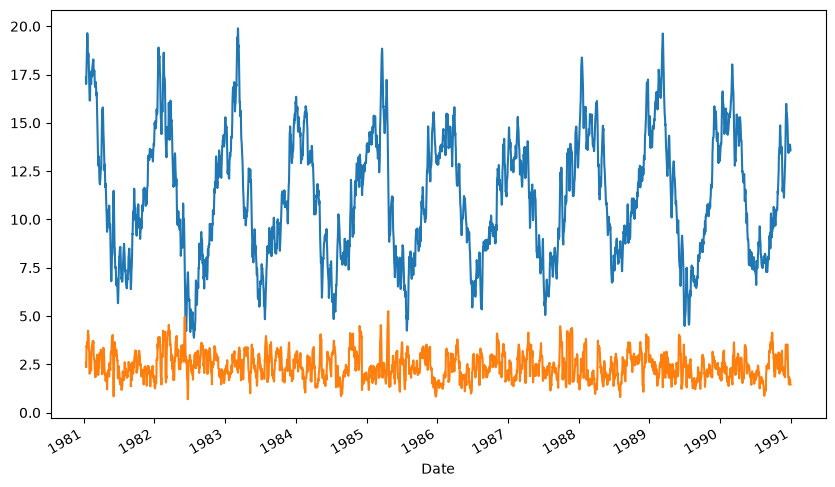

In [ ]:
# Code tại đây
plt.figure(figsize=(10, 6))

# Rolling mean is a method calculate avarage a set of value in over a period of time
# Window=12 -> 12 Tháng
rolling_mean = df['Temp'].rolling(window=12).mean()
print(rolling_mean)
rolling_mean.plot()

# Std: Độ lệch chuẩn
rolling_std = df['Temp'].rolling(window=12).std()
print(rolling_std)
rolling_std.plot()

plt.savefig(output_dir / "figure_05_1.png", dpi=300, bbox_inches="tight")

plt.show()

#### Ghi chú đồ thị: Rolling mean & rolling std

- **Công dụng**
  - Kiểm tra tính dừng bằng mắt: mean và std có thay đổi theo thời gian không
  - Làm trơn chuỗi để thấy xu hướng
- **Ưu điểm**
  - Dễ hiểu, dễ tính
  - Rolling std cho thấy giai đoạn biến động mạnh/yếu
- **Nhược điểm**
  - Phụ thuộc `window`: nhỏ → còn nhiễu; lớn → mất chi tiết và mất (window − 1) điểm đầu
  - Chỉ là cảm quan, phải kèm ADF mới kết luận được
- **Lưu ý cho bài này**
  - Dữ liệu theo **ngày** nên `window=12` = 12 ngày, không phải 12 tháng như comment ghi → muốn xem theo năm dùng `window=365`, hoặc dùng chuỗi `monthly` với `window=12`
  - Đồ thị chưa có legend → thêm `label="Rolling mean"`, `label="Rolling std"` và `plt.legend()`

### 3. Vẽ seasonal plot theo tháng (đối với dữ liệu theo tháng)


In [ ]:
# Code tại đây
additive = seasonal_decompose(df, model='additive', period=365)

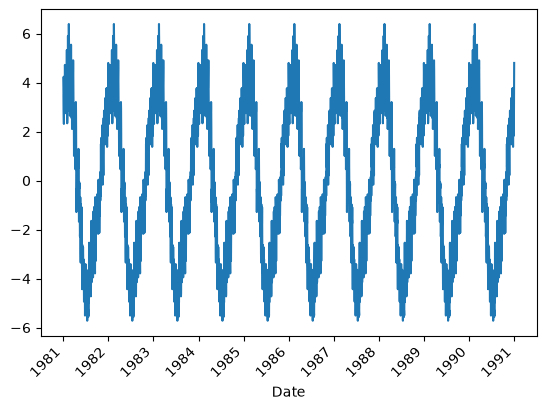

In [ ]:
additive.seasonal.plot()
plt.xticks(rotation=45, fontsize=10)

plt.savefig(output_dir / "figure_05_2.png", dpi=300, bbox_inches="tight")

plt.show()

#### Ghi chú đồ thị: Thành phần Seasonal (classical, period = 365)

- **Công dụng**
  - Xem hình dạng mùa vụ lặp lại mỗi năm
- **Ưu điểm**
  - Thấy rõ chu kỳ năm: ấm đầu năm, lạnh giữa năm (mùa đông Nam bán cầu)
- **Nhược điểm**
  - Classical decomposition giả định mùa vụ y hệt nhau mọi năm → 10 năm giống nhau, không thấy năm nào bất thường
  - Mỗi ngày trong năm chỉ được trung bình từ khoảng 9 năm → đường răng cưa, nhiễu
  - Đây là thành phần seasonal, chưa phải *seasonal plot* đúng nghĩa (mỗi năm 1 đường, trục x là tháng)

### 4. Vẽ heatmap seasonality (month × year)


In [ ]:
df_heatmap = df.copy()
df_heatmap['Year'] = df_heatmap.index.year
df_heatmap['Month'] = df_heatmap.index.month

df_heatmap_pivot = pd.pivot_table(df, values="Temp", index=df_heatmap['Month'], columns=df_heatmap['Year'], aggfunc='mean')

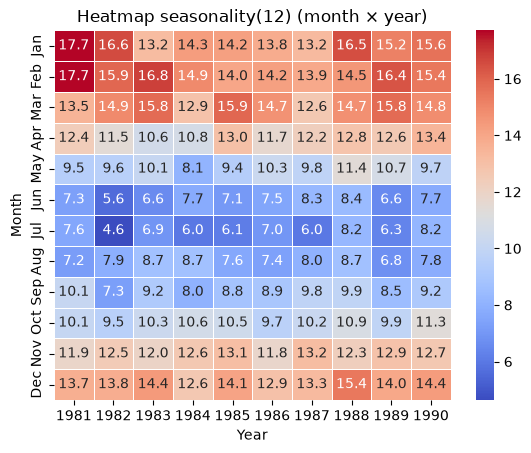

In [ ]:
list_month = ['Jan', 'Feb', 'Mar', 'Apr', 'May', 'Jun', 'Jul', 'Aug', 'Sep', 'Oct', 'Nov', 'Dec']

plt.Figure(figsize=(12,6))

sns.heatmap(df_heatmap_pivot,
            cmap='coolwarm',
            yticklabels = list_month,
            fmt=".1f",
            linewidth=.5,
            annot=True)
plt.title("Heatmap seasonality(12) (month × year)")

plt.savefig(output_dir / "figure_05_3.png", dpi=300, bbox_inches="tight")

plt.show()

#### Ghi chú đồ thị: Heatmap tháng × năm

- **Công dụng**
  - Xem nhiệt độ trung bình từng tháng của từng năm trên 1 hình
- **Ưu điểm**
  - Đọc theo hàng (tháng) → thấy mùa vụ; đọc theo cột (năm) → thấy năm nóng/lạnh bất thường
  - Có số cụ thể trên từng ô (`annot=True`)
- **Nhược điểm**
  - Mất chi tiết theo ngày (chỉ còn trung bình tháng)
  - Màu khó phân biệt chênh lệch nhỏ (1–2°C) → phải đọc số
- **Lưu ý cho bài này**
  - `plt.Figure(figsize=(12,6))` (chữ F hoa) không có tác dụng → hình nhỏ, số chen chúc; sửa thành `plt.figure(figsize=(12, 6))`

### 5. Kết luận: Xu hướng chung, các mùa vụ nổi bật, bất thường (nếu có)

Xu hướng chung theo từng các năm, kết luận dựa trên trung bình nhiệt độ từng tháng

Trong khoảng từ tháng 1 đến tháng 3, nhiệt độ trung bình dao động từ 14 -> 18 độ


Tháng 4 bắt đầu trở lại và đến Tháng 10: 6 -> 13 độ

Tháng 11 trở đi bắt đầu ấm dần trở lại dao động khoảng 11 -> 15 độ


Có thể thấy nhiệt độ theo chu kỳ 12 tháng, không có sự thay đổi lớn qua từng các năm, có thể chỉ chênh nhau 1 -> 3 độ